# KSA consumer spending nowcast: monthly POS spending by sector
**Author:** Amir Khan · **Data:** Saudi Central Bank (SAMA) weekly point-of-sale bulletin, via the KAPSARC Data Portal (public domain label)

Business question: *how much will Saudi card spending at points of sale be next month and over the next six months, by merchant sector, and how much of the month-to-month swing is just Ramadan and Eid moving through the Gregorian calendar?*

This notebook runs the same pipeline as `make all` (code in `src/nowcast/`) and shows the results.
On Kaggle: attach this repository as a dataset (or `git clone` it) and run all cells.

In [1]:
import os, sys, subprocess, pathlib
# Locate the repo root (local checkout, or Kaggle /kaggle/input/<dataset> / /kaggle/working)
cands = [pathlib.Path.cwd(), pathlib.Path.cwd().parent, *pathlib.Path('/kaggle/input').glob('*'), pathlib.Path('/kaggle/working/ksa-consumer-spending-nowcast')]
ROOT = next(p for p in cands if (p / 'src' / 'nowcast').exists())
if os.path.exists('/kaggle'):
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'hijridate==2.3.0'], check=True)
    if not os.access(ROOT, os.W_OK):  # Kaggle inputs are read-only: copy to working dir
        subprocess.run(['cp', '-r', str(ROOT), '/kaggle/working/ksa-consumer-spending-nowcast'], check=True)
        ROOT = pathlib.Path('/kaggle/working/ksa-consumer-spending-nowcast')
sys.path.insert(0, str(ROOT / 'src'))
print(ROOT)

.


In [2]:
import json, pandas as pd, matplotlib.pyplot as plt
from IPython.display import Image, display, Markdown
from nowcast import config as C
from nowcast.pipeline import main
# Full run: data -> Hijri features -> rolling-origin backtest -> forecasts -> figures (about 2 minutes)
results = main(refresh=False)

series=18 months=2020-07..2026-02


./src/nowcast/pipeline.py:67: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  "nowcast": nc.round(3).astype({"ds": str}).to_dict(orient="records"),


{
 "hijri_ablation": {
  "SARIMAX_mean_MAPE": 7.21,
  "SARIMA_noHijri_mean_MAPE": 8.87,
  "sectors_where_hijri_regressors_help": 11,
  "by_sector": {
   "Beverage and Food": {
    "SARIMAX": 5.05,
    "SARIMA_noHijri": 4.66
   },
   "Clothing and Footwear": {
    "SARIMAX": 10.4,
    "SARIMA_noHijri": 17.94
   },
   "Construction & Building Materials": {
    "SARIMAX": 3.67,
    "SARIMA_noHijri": 3.6
   },
   "Education": {
    "SARIMAX": 7.5,
    "SARIMA_noHijri": 15.77
   },
   "Electronic & Electric Devices": {
    "SARIMAX": 13.64,
    "SARIMA_noHijri": 14.89
   },
   "Furniture": {
    "SARIMAX": 6.16,
    "SARIMA_noHijri": 6.25
   },
   "Gas Stations": {
    "SARIMAX": 3.42,
    "SARIMA_noHijri": 3.72
   },
   "Health": {
    "SARIMAX": 3.32,
    "SARIMA_noHijri": 2.48
   },
   "Hotels": {
    "SARIMAX": 6.66,
    "SARIMA_noHijri": 6.5
   },
   "Jewelry": {
    "SARIMAX": 11.65,
    "SARIMA_noHijri": 17.46
   },
   "Miscellaneous Goods and Services": {
    "SARIMAX": 8.22,
    "S

## 1. Data: weekly bulletins spliced and converted to calendar months

In [3]:
audit = pd.read_csv(C.PROCESSED / 'splice_audit.csv')
display(audit)
display(pd.read_csv(C.PROCESSED / 'data_corrections.csv'))
m = pd.read_csv(C.PROCESSED / 'monthly_sector_value.csv', parse_dates=['ds'])
m.groupby('unique_id').ds.agg(['min', 'max', 'count'])

,sector,b_sector,overlap_weeks,max_rel_gap_pct,spliced
0,Total,20.Total,2,0.000,True
1,Beverage and Food,6.Food & Beverages,2,0.000,True
2,Gas Stations,17.Gas Stations,2,0.094,True
3,Hotels,5.Hotels,2,0.000,True
4,Public Utilities,16.Public Utilities & Services,2,0.000,True
5,Transportation,1. Transportation,2,37.739,False
6,Health,2.Health,2,20.734,False
7,Restaurants & Café,3.Restaurants & Café,2,12.360,False
8,Clothing and Footwear,"7.Apparel, Clothing & Accessories",2,6.117,False
9,Jewelry,13.Jewelry,2,8.447,False


,sector,week_start,reported_k_sar,neighbour_median_k_sar,replaced_with_k_sar
0,Gas Stations,2026-02-01,63280.0,897895.0,1016941.0


,min,max,count
unique_id,,,
Beverage and Food,2020-07-01,2026-02-01,68
Clothing and Footwear,2020-07-01,2025-06-01,60
Construction & Building Materials,2020-07-01,2025-06-01,60
Education,2020-07-01,2025-06-01,60
Electronic & Electric Devices,2020-07-01,2025-06-01,60
Furniture,2020-07-01,2025-06-01,60
Gas Stations,2020-07-01,2026-02-01,68
Health,2020-07-01,2025-06-01,60
Hotels,2020-07-01,2026-02-01,68


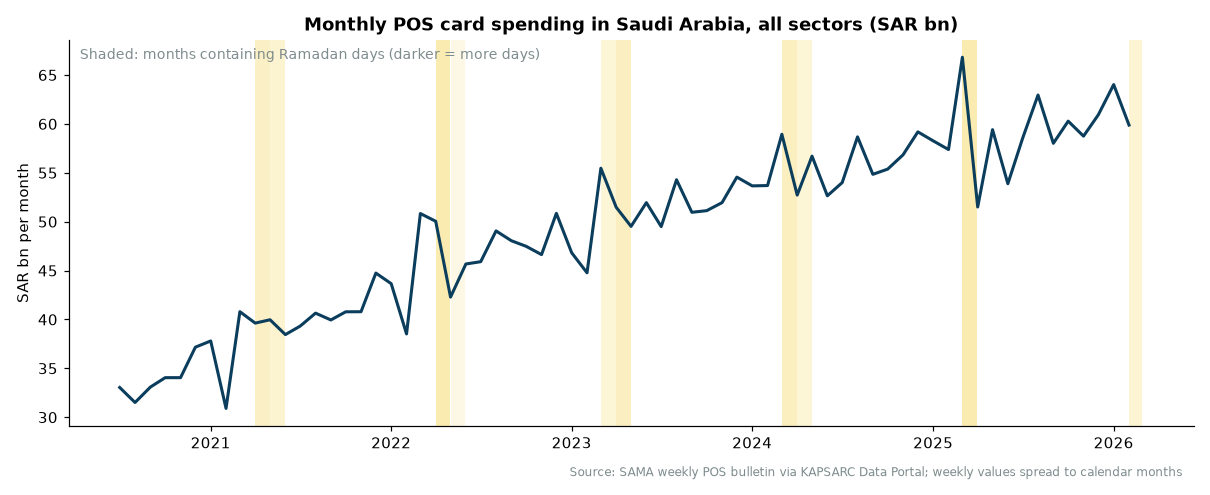

In [4]:
display(Image(str(C.FIGURES / '01_total_monthly_history.png')))

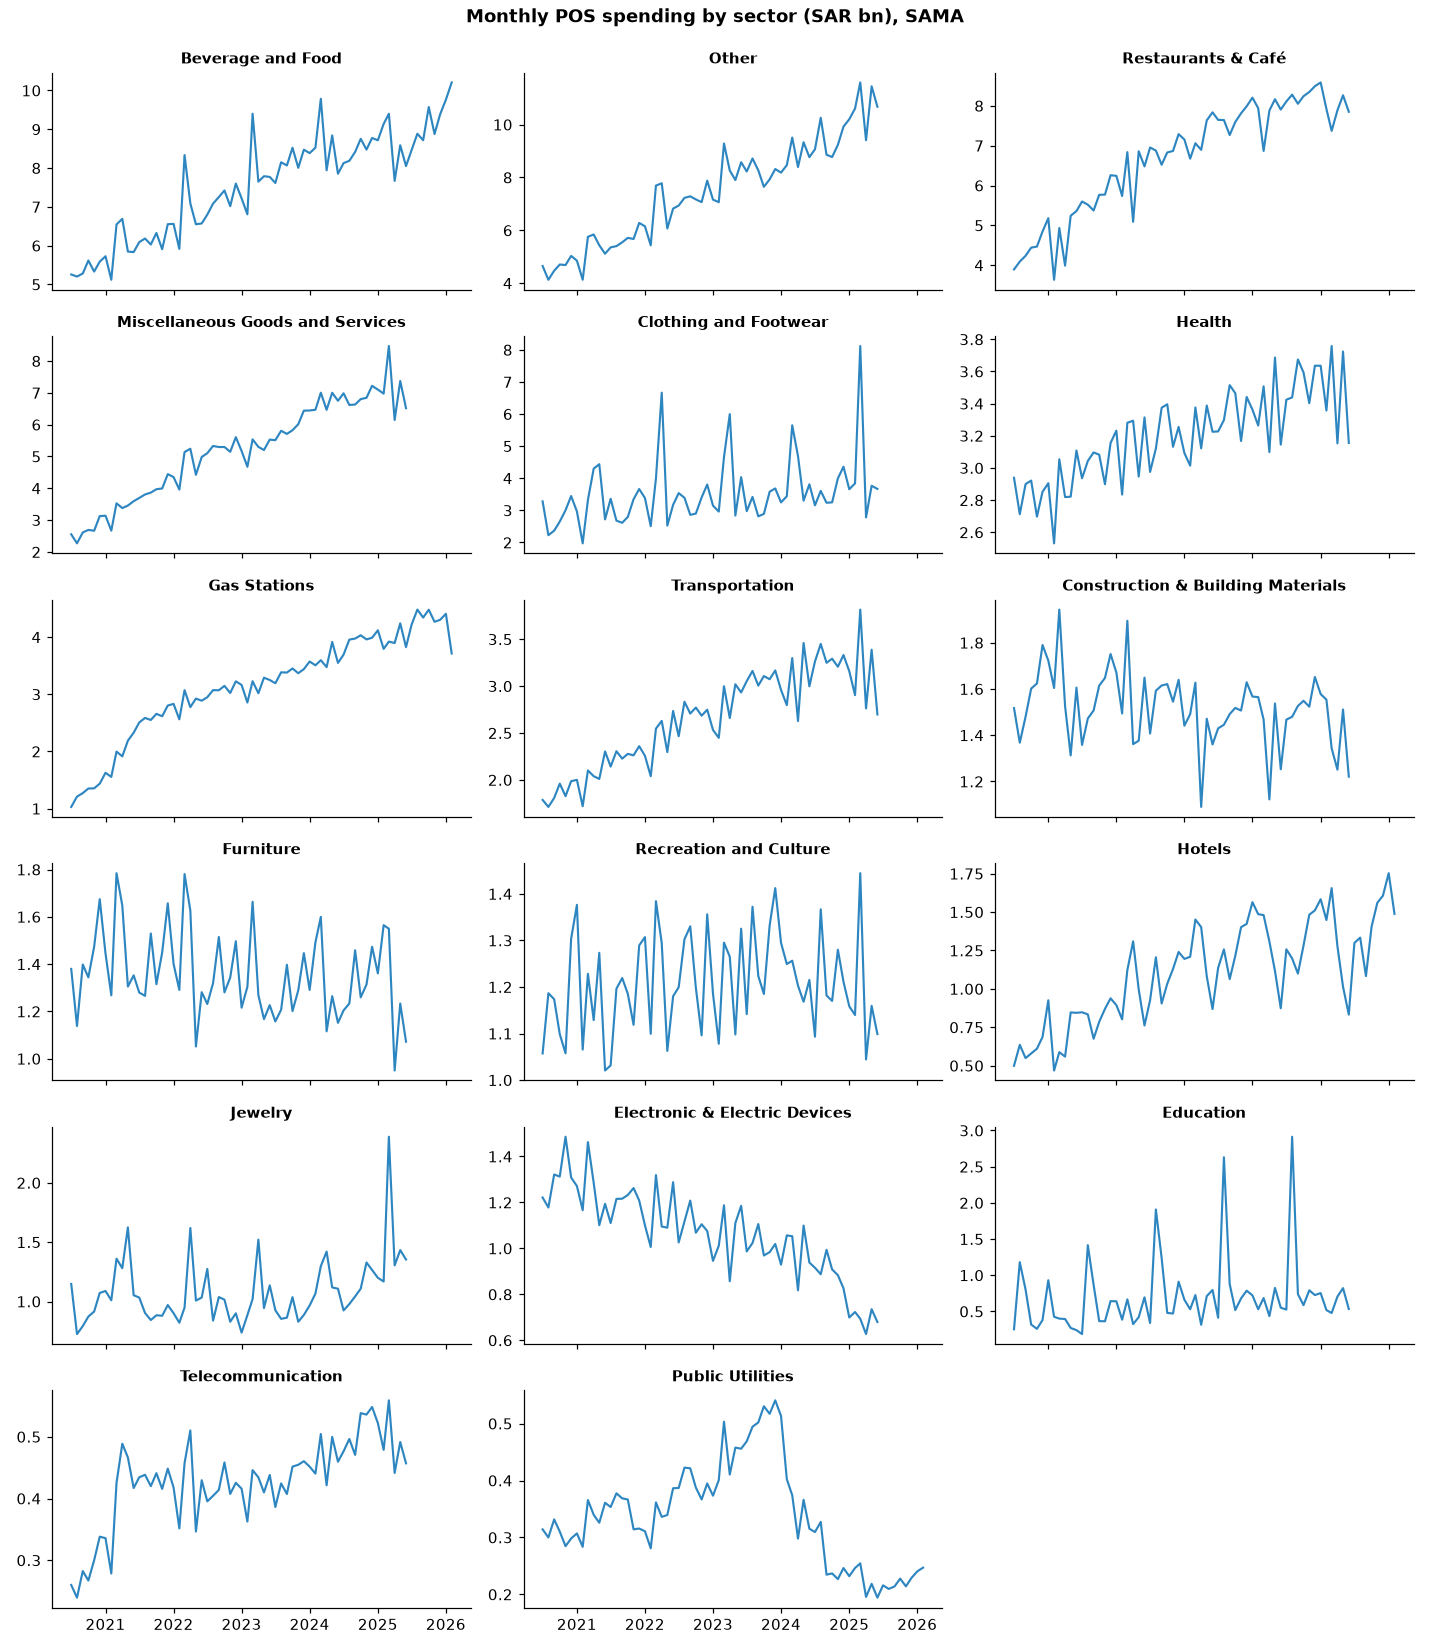

In [5]:
display(Image(str(C.FIGURES / '02_sector_small_multiples.png')))

## 2. Hijri calendar features
Ramadan, the last ten nights, Eid al-Fitr and Eid al-Adha days per Gregorian month, from the Umm al-Qura calendar (`hijridate`).

In [6]:
cal = pd.read_csv(C.PROCESSED / 'calendar_features.csv', parse_dates=['ds'])
cal[(cal.ds >= '2025-01-01') & (cal.ds <= '2026-08-01')]

,ds,ramadan_days,ramadan_last10_days,eid_fitr_days,eid_adha_days,weekend_days,days_in_month,ramadan_flag,eid_flag
72,2025-01-01,0,0,0,0,9,31,0,0
73,2025-02-01,0,0,0,0,8,28,0,0
74,2025-03-01,29,10,2,0,9,31,1,1
75,2025-04-01,0,0,1,0,8,30,0,1
76,2025-05-01,0,0,0,0,10,31,0,0
77,2025-06-01,0,0,0,5,8,30,0,1
78,2025-07-01,0,0,0,0,8,31,0,0
79,2025-08-01,0,0,0,0,10,31,0,0
80,2025-09-01,0,0,0,0,8,30,0,0
81,2025-10-01,0,0,0,0,9,31,0,0


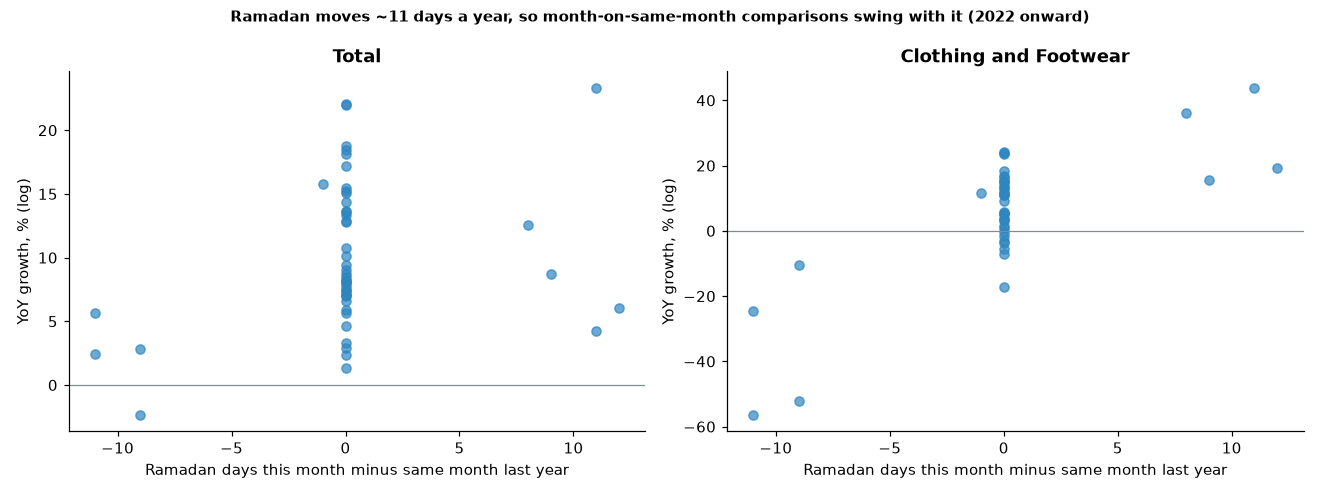

In [7]:
display(Image(str(C.FIGURES / '06_ramadan_shift_effect.png')))

## 3. Rolling-origin backtest (12 origins, horizons 1-6 months, refit every origin)

In [8]:
sc = pd.read_csv(C.PROCESSED / 'backtest_scores.csv')
pd.options.display.float_format = '{:.2f}'.format
display(sc.pivot(index='unique_id', columns='model', values='MAPE'))
display(sc.pivot(index='unique_id', columns='model', values='sMAPE'))
display(sc[sc.model != 'SARIMA_noHijri'].groupby('model')[['MAPE', 'sMAPE', 'MAPE_h1']].mean())

model,ETS,LightGBM,SARIMAX,SARIMA_noHijri,SeasonalNaive
unique_id,,,,,
Beverage and Food,4.51,4.97,5.05,4.66,6.36
Clothing and Footwear,23.22,17.24,10.40,17.94,18.70
Construction & Building Materials,7.05,3.16,3.67,3.60,3.29
Education,33.51,17.33,7.50,15.77,14.27
Electronic & Electric Devices,18.36,16.41,13.64,14.89,31.37
Furniture,9.51,6.97,6.16,6.25,5.29
Gas Stations,4.60,4.88,3.42,3.72,8.15
Health,4.67,3.65,3.32,2.48,4.00
Hotels,13.30,6.08,6.66,6.50,6.02


model,ETS,LightGBM,SARIMAX,SARIMA_noHijri,SeasonalNaive
unique_id,,,,,
Beverage and Food,4.51,5.07,5.13,4.75,6.60
Clothing and Footwear,20.05,15.12,9.83,16.40,17.93
Construction & Building Materials,6.91,3.22,3.67,3.62,3.30
Education,29.27,16.32,7.40,15.67,14.51
Electronic & Electric Devices,16.15,14.49,12.30,13.30,26.36
Furniture,9.31,6.82,5.78,6.04,5.15
Gas Stations,4.65,4.71,3.36,3.64,8.53
Health,4.61,3.67,3.30,2.47,4.11
Hotels,12.99,6.03,6.76,6.64,6.19


,MAPE,sMAPE,MAPE_h1
model,,,
ETS,11.25,10.76,9.55
LightGBM,9.51,9.56,7.87
SARIMAX,7.21,7.21,5.45
SeasonalNaive,11.25,11.09,11.17


In [9]:
best = pd.DataFrame(results['best_by_sector']).T.sort_values('MAPE')
display(best)
print('Wins by model:', results['wins_by_model'])
print('Hijri ablation (SARIMA with vs without holiday regressors):',
      {k: v for k, v in results['hijri_ablation'].items() if k != 'by_sector'})

,model,MAPE,sMAPE,MAPE_h1,SeasonalNaive_MAPE
Construction & Building Materials,LightGBM,3.16,3.22,3.11,3.29
Total,SARIMAX,3.17,3.13,3.73,5.55
Health,SARIMAX,3.32,3.30,2.50,4.00
Gas Stations,SARIMAX,3.42,3.36,2.42,8.15
Restaurants & Café,SARIMAX,4.03,3.98,3.05,4.04
Other,LightGBM,4.20,4.21,3.97,15.94
Beverage and Food,ETS,4.51,4.51,4.51,6.36
Furniture,SeasonalNaive,5.29,5.15,4.91,5.29
Transportation,SARIMAX,5.89,5.75,5.09,6.47
Hotels,SeasonalNaive,6.02,6.19,6.24,6.02


Wins by model: {'SARIMAX': 11, 'ETS': 3, 'LightGBM': 2, 'SeasonalNaive': 2}
Hijri ablation (SARIMA with vs without holiday regressors): {'SARIMAX_mean_MAPE': np.float64(7.21), 'SARIMA_noHijri_mean_MAPE': np.float64(8.87), 'sectors_where_hijri_regressors_help': 11}


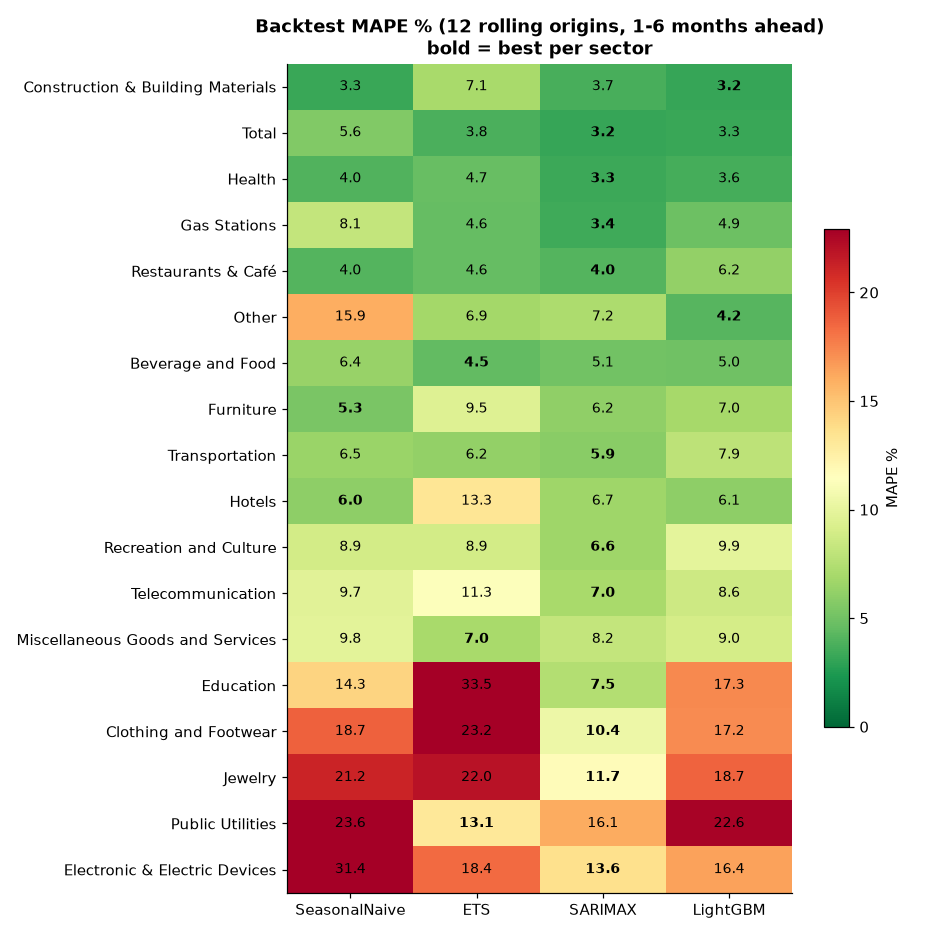

In [10]:
display(Image(str(C.FIGURES / '03_backtest_mape_heatmap.png')))

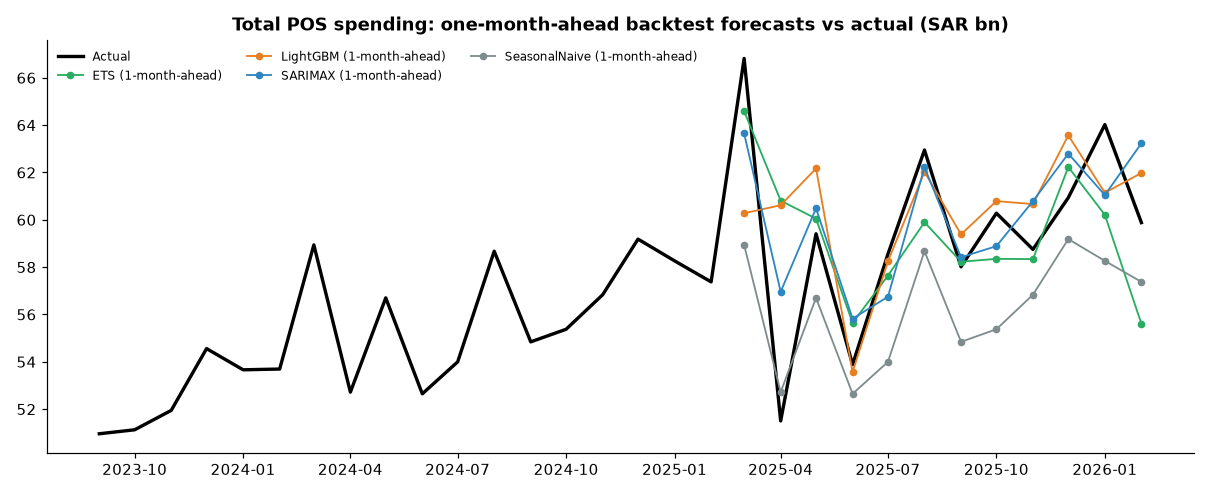

In [11]:
display(Image(str(C.FIGURES / '04_backtest_total_h1.png')))

## 4. Six-month forecast with 80% intervals (best backtest model per sector)

In [12]:
fc = pd.read_csv(C.PROCESSED / 'forecast_best_model.csv', parse_dates=['ds'])
fc[fc.unique_id.isin(['Total', 'Beverage and Food', 'Restaurants & Café'])]

,unique_id,model,ds,h,yhat,lo80,hi80
0,Beverage and Food,ETS,2026-03-01,1,10.10,9.44,10.71
1,Beverage and Food,ETS,2026-04-01,2,8.32,7.85,8.91
2,Beverage and Food,ETS,2026-05-01,3,9.38,9.21,10.05
3,Beverage and Food,ETS,2026-06-01,4,8.79,8.64,9.47
4,Beverage and Food,ETS,2026-07-01,5,9.21,9.01,9.95
5,Beverage and Food,ETS,2026-08-01,6,9.59,9.37,10.42
72,Restaurants & Café,SARIMAX,2025-07-01,1,8.15,7.83,8.55
73,Restaurants & Café,SARIMAX,2025-08-01,2,8.32,8.05,8.76
74,Restaurants & Café,SARIMAX,2025-09-01,3,8.09,7.59,8.40
75,Restaurants & Café,SARIMAX,2025-10-01,4,8.28,7.67,8.50


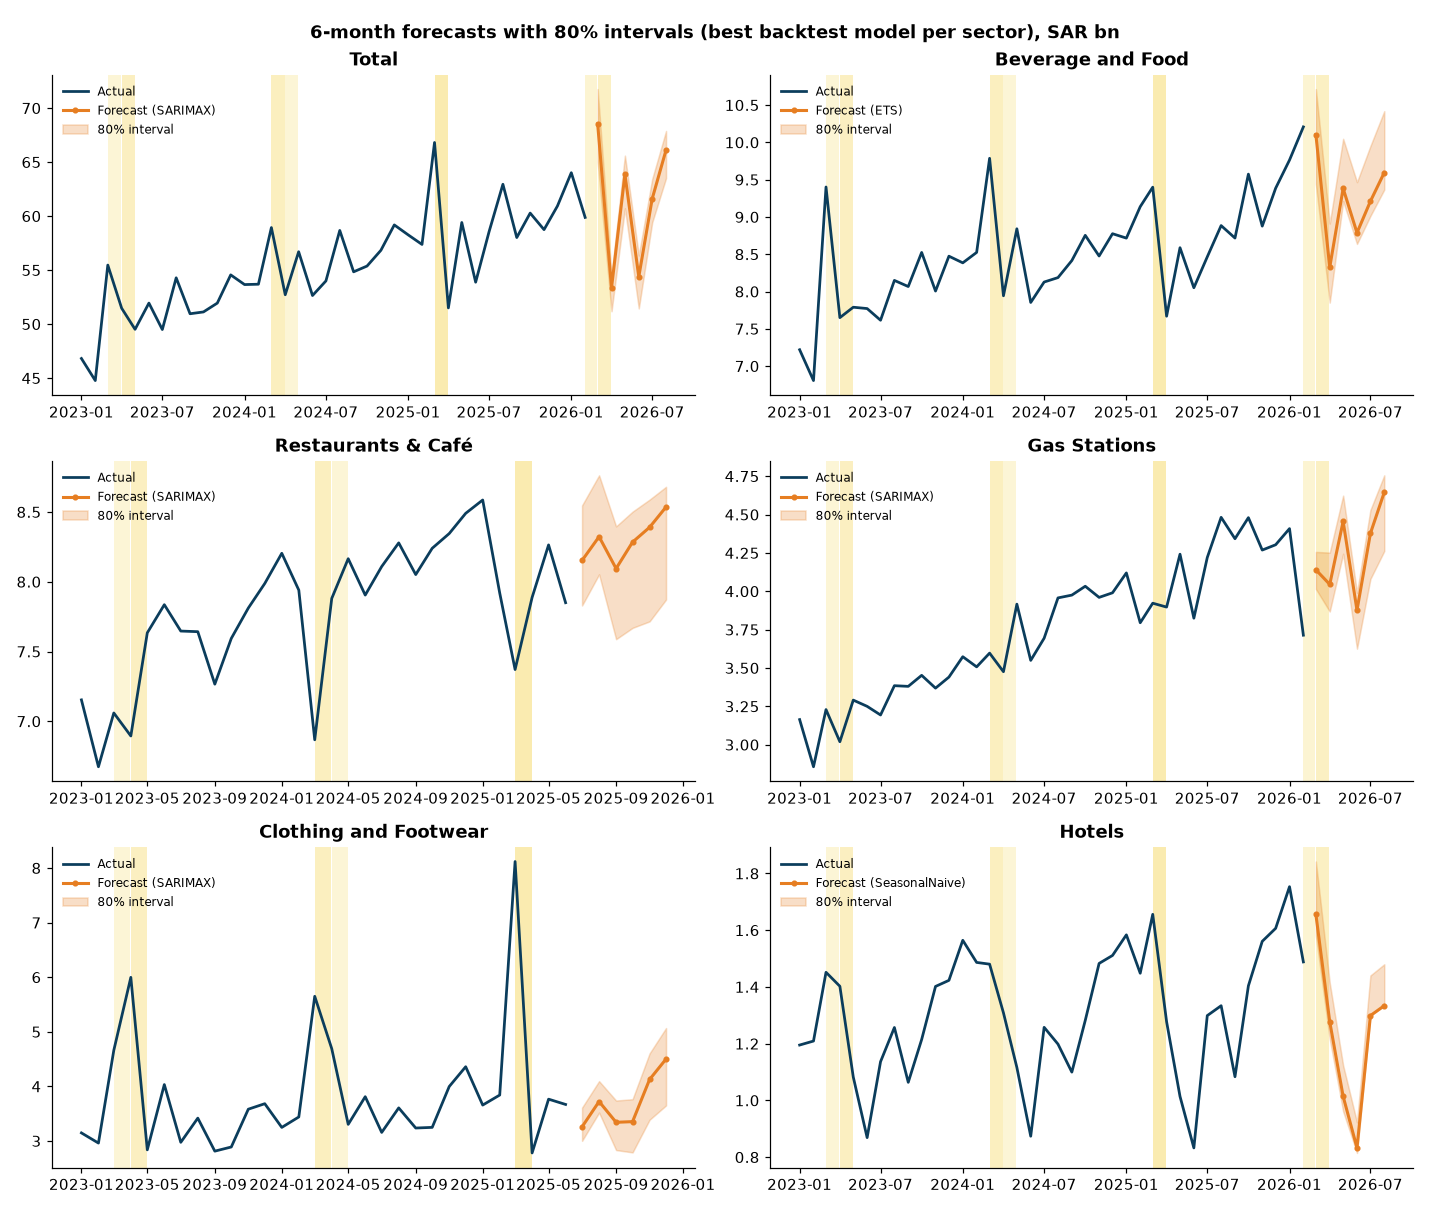

In [13]:
display(Image(str(C.FIGURES / '05_forecast_fans.png')))

## 5. Nowcast check on the partially observed month
The bulletin ends part-way through a month. The observed days are a hard floor for that month's total.

In [14]:
pd.read_csv(C.PROCESSED / 'nowcast_partial_month.csv')

,unique_id,ds,y_obs,days,last_day,yhat,lo80,hi80,model,observed_share_of_forecast_pct
0,Telecommunication,2025-07-01,0.21,12,2025-07-12,0.48,0.45,0.49,SARIMAX,45.01
1,Restaurants & Café,2025-07-01,3.32,12,2025-07-12,8.15,7.83,8.55,SARIMAX,40.68
2,Recreation and Culture,2025-07-01,0.47,12,2025-07-12,1.03,0.96,1.06,SARIMAX,45.08
3,Transportation,2025-07-01,1.28,12,2025-07-12,3.05,2.78,3.19,SARIMAX,41.86
4,Other,2025-07-01,4.71,12,2025-07-12,10.75,10.04,11.35,LightGBM,43.80
5,Miscellaneous Goods and Services,2025-07-01,2.79,12,2025-07-12,7.24,6.51,7.73,ETS,38.55
6,Jewelry,2025-07-01,0.54,12,2025-07-12,1.16,1.09,1.36,SARIMAX,46.76
7,Health,2025-07-01,1.43,12,2025-07-12,3.48,3.36,3.59,SARIMAX,41.00
8,Furniture,2025-07-01,0.48,12,2025-07-12,1.20,1.13,1.26,SeasonalNaive,40.09
9,Electronic & Electric Devices,2025-07-01,0.30,12,2025-07-12,0.65,0.56,0.68,SARIMAX,46.59


## Limitations
* 60-68 complete months per sector (Jul 2020 onward), so the backtest covers only 12 origins; differences under ~0.5 pp MAPE are noise.
* 12 of 17 sectors stop in June 2025 because SAMA re-cut its sector list in mid-2025; only series that match the new bulletin within 1% are extended.
* Weekly values are spread evenly over 7 days to build calendar months.
* Intervals come from empirical backtest errors (few per horizon) and are not independently validated.